# 04 — Global LightGBM model

This notebook trains one global model for every store-family series, evaluates the untouched 16-day validation horizon with RMSLE, compares it against the `mean_28` baseline, analyzes errors, and creates a Kaggle submission.

## 1. Installation

Run once from CMD in the project root if LightGBM is not installed:

```cmd
uv add lightgbm
```

If the project does not use `pyproject.toml`, run `uv pip install lightgbm`.

In [1]:
from pathlib import Path
import json
import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.metrics import mean_squared_log_error

SEED = 42
BASELINE_RMSLE = 0.521588
np.random.seed(SEED)

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data' / 'interim').exists() and (PROJECT_ROOT.parent / 'data' / 'interim').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

INTERIM_DIR = PROJECT_ROOT / 'data' / 'interim'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
MODELS_DIR = PROJECT_ROOT / 'models'
REPORTS_DIR = PROJECT_ROOT / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'
for directory in [PROCESSED_DIR, MODELS_DIR, REPORTS_DIR, FIGURES_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print('LightGBM:', lgb.__version__)
print('Project root:', PROJECT_ROOT)

LightGBM: 4.7.0
Project root: retail-demand-forecasting


## 2. Load feature tables

In [2]:
paths = {
    'train': INTERIM_DIR / 'features_train.parquet',
    'validation': INTERIM_DIR / 'features_validation.parquet',
    'test': INTERIM_DIR / 'features_test.parquet',
}
missing = [str(path) for path in paths.values() if not path.exists()]
assert not missing, f'Missing feature files: {missing}'

train_pl = pl.read_parquet(paths['train'])
validation_pl = pl.read_parquet(paths['validation'])
test_pl = pl.read_parquet(paths['test'])

assert train_pl.height == 342_144
assert validation_pl.height == 28_512
assert test_pl.height == 28_512
assert 'sales' in train_pl.columns and 'sales' in validation_pl.columns
assert 'sales' not in test_pl.columns

print('train:     ', train_pl.shape)
print('validation:', validation_pl.shape)
print('test:      ', test_pl.shape)

train:      (342144, 40)
validation: (28512, 40)
test:       (28512, 39)


## 3. Select model features

Dates, row identifiers, and the target are excluded. `cutoff_date` identifies the backtesting window rather than a future-known business variable, so it is also excluded. LightGBM receives missing lag values directly.

In [3]:
TARGET = 'sales'
DROP_COLUMNS = {'sales', 'id', 'date', 'cutoff_date'}
CATEGORICAL_COLUMNS = ['family', 'city', 'state', 'type']

feature_columns = [
    column for column in train_pl.columns
    if column not in DROP_COLUMNS
]

assert set(feature_columns).issubset(validation_pl.columns)
assert set(feature_columns).issubset(test_pl.columns)
assert set(CATEGORICAL_COLUMNS).issubset(feature_columns)

print(f'Features: {len(feature_columns)}')
print(feature_columns)

Features: 36
['store_nbr', 'family', 'onpromotion', 'sales_mean_28', 'sales_std_28', 'sales_min_28', 'sales_max_28', 'zero_rate_28', 'sales_mean_14', 'sales_mean_7', 'sales_mean_prev7', 'sales_trend_7', 'sales_lag_16', 'sales_lag_21', 'sales_lag_28', 'sales_lag_35', 'city', 'state', 'type', 'cluster', 'dcoilwtico', 'is_holiday', 'has_holiday_type', 'has_event', 'holiday_count', 'day_of_forecast', 'day_of_week', 'day_of_month', 'month', 'year', 'is_weekend', 'day_of_year', 'sales_lag_16_missing', 'sales_lag_21_missing', 'sales_lag_28_missing', 'sales_lag_35_missing']


## 4. Convert to pandas and align categories

The target is transformed with `log1p`, making the training objective consistent with RMSLE. Category levels are defined jointly so their internal codes match across train, validation, and test.

In [4]:
X_train = train_pl.select(feature_columns).to_pandas()
X_validation = validation_pl.select(feature_columns).to_pandas()
X_test = test_pl.select(feature_columns).to_pandas()

y_train = train_pl[TARGET].to_numpy()
y_validation = validation_pl[TARGET].to_numpy()
y_train_log = np.log1p(y_train)
y_validation_log = np.log1p(y_validation)

category_levels = {}
for column in CATEGORICAL_COLUMNS:
    levels = sorted(set(X_train[column].dropna()) | set(X_validation[column].dropna()) | set(X_test[column].dropna()))
    category_levels[column] = levels
    X_train[column] = pd.Categorical(X_train[column], categories=levels)
    X_validation[column] = pd.Categorical(X_validation[column], categories=levels)
    X_test[column] = pd.Categorical(X_test[column], categories=levels)

assert list(X_train.columns) == list(X_validation.columns) == list(X_test.columns)
assert np.isfinite(y_train_log).all() and np.isfinite(y_validation_log).all()
print('Matrices:', X_train.shape, X_validation.shape, X_test.shape)

Matrices: (342144, 36) (28512, 36) (28512, 36)


## 5. Train with early stopping

In [5]:
model = lgb.LGBMRegressor(
    objective='regression_l2',
    n_estimators=3_000,
    learning_rate=0.03,
    num_leaves=63,
    max_depth=-1,
    min_child_samples=40,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1,
    verbosity=-1,
)

model.fit(
    X_train,
    y_train_log,
    eval_set=[(X_validation, y_validation_log)],
    eval_metric='rmse',
    categorical_feature=CATEGORICAL_COLUMNS,
    callbacks=[
        lgb.early_stopping(stopping_rounds=150, verbose=True),
        lgb.log_evaluation(period=100),
    ],
)

print('Best iteration:', model.best_iteration_)

retail-demand-forecasting/.venv/Lib/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 150 rounds
[100]	valid_0's rmse: 0.464136	valid_0's l2: 0.215423
[200]	valid_0's rmse: 0.440298	valid_0's l2: 0.193862
[300]	valid_0's rmse: 0.435919	valid_0's l2: 0.190026
[400]	valid_0's rmse: 0.434656	valid_0's l2: 0.188926
[500]	valid_0's rmse: 0.433681	valid_0's l2: 0.188079
[600]	valid_0's rmse: 0.432148	valid_0's l2: 0.186752
[700]	valid_0's rmse: 0.430987	valid_0's l2: 0.18575
[800]	valid_0's rmse: 0.430341	valid_0's l2: 0.185193
[900]	valid_0's rmse: 0.429875	valid_0's l2: 0.184792
[1000]	valid_0's rmse: 0.429402	valid_0's l2: 0.184386
[1100]	valid_0's rmse: 0.429029	valid_0's l2: 0.184066
[1200]	valid_0's rmse: 0.428832	valid_0's l2: 0.183897
[1300]	valid_0's rmse: 0.428539	valid_0's l2: 0.183646
[1400]	valid_0's rmse: 0.428333	valid_0's l2: 0.183469
[1500]	valid_0's rmse: 0.428104	valid_0's l2: 0.183273
[1600]	valid_0's rmse: 0.428031	valid_0's l2: 0.18321
Early stopping, best iteration is:
[1508]	valid_0's rmse: 0.427997	va

## 6. Evaluate against the baseline

In [6]:
validation_pred_log = model.predict(
    X_validation,
    num_iteration=model.best_iteration_,
)
validation_pred = np.maximum(0, np.expm1(validation_pred_log))

model_rmsle = np.sqrt(mean_squared_log_error(y_validation, validation_pred))
baseline_pred = np.maximum(0, validation_pl['sales_mean_28'].to_numpy())
baseline_check = np.sqrt(mean_squared_log_error(y_validation, baseline_pred))
improvement = (BASELINE_RMSLE - model_rmsle) / BASELINE_RMSLE * 100

results = pl.DataFrame({
    'model': ['mean_28 baseline', 'LightGBM'],
    'rmsle': [baseline_check, model_rmsle],
})
display(results)
print(f'Official baseline reference: {BASELINE_RMSLE:.6f}')
print(f'LightGBM RMSLE:            {model_rmsle:.6f}')
print(f'Relative improvement:      {improvement:.2f}%')
print('RESULT:', 'LightGBM beats the baseline.' if model_rmsle < BASELINE_RMSLE else 'LightGBM does not beat the baseline yet.')

model,rmsle
str,f64
"""mean_28 baseline""",0.521588
"""LightGBM""",0.427991


Official baseline reference: 0.521588
LightGBM RMSLE:            0.427991
Relative improvement:      17.94%
RESULT: LightGBM beats the baseline.


## 7. Error analysis by family and forecast day

In [7]:
evaluation = validation_pl.select(
    'date', 'store_nbr', 'family', 'day_of_forecast', 'sales'
).with_columns(pl.Series('prediction', validation_pred))

evaluation = evaluation.with_columns(
    (
        pl.col('prediction').log1p()
        - pl.col('sales').log1p()
    ).pow(2).alias('squared_log_error')
)

family_error = (
    evaluation.group_by('family')
    .agg(
        pl.col('squared_log_error').mean().sqrt().alias('rmsle'),
        pl.col('sales').sum().alias('actual_sales'),
        pl.col('prediction').sum().alias('predicted_sales'),
    )
    .sort('rmsle', descending=True)
)

horizon_error = (
    evaluation.group_by('day_of_forecast')
    .agg(
        pl.col('squared_log_error').mean().sqrt().alias('rmsle'),
        pl.col('sales').sum().alias('actual_sales'),
        pl.col('prediction').sum().alias('predicted_sales'),
    )
    .sort('day_of_forecast')
)

print('Most difficult families:')
display(family_error.head(10))
print('Error across the horizon:')
display(horizon_error)

Most difficult families:


family,rmsle,actual_sales,predicted_sales
str,f64,f64,f64
"""SCHOOL AND OFFICE SUPPLIES""",1.053984,51795.0,9432.65909
"""GROCERY II""",0.655079,25031.0,28256.781825
"""LINGERIE""",0.632063,6716.0,5208.610613
"""CELEBRATION""",0.548938,10768.0,10098.258409
"""HARDWARE""",0.52977,1252.0,1018.711103
"""MAGAZINES""",0.525196,6146.0,4988.345903
"""AUTOMOTIVE""",0.517068,6381.0,5524.441556
"""SEAFOOD""",0.504563,17260.919022,16066.738346
"""LADIESWEAR""",0.499822,8711.0,9766.827576


Error across the horizon:


day_of_forecast,rmsle,actual_sales,predicted_sales
i8,f64,f64,f64
1,0.409348,885856.84087,765743.073405
2,0.401862,988527.763204,882521.756567
3,0.405673,964712.016051,905080.141031
4,0.422051,728068.485132,779502.379317
5,0.434013,827775.686128,863648.094626
…,…,…,…
12,0.463404,826373.722022,776545.502073
13,0.457749,792630.535079,959983.615244
14,0.456544,865639.677471,1.0828e6


## 8. Feature importance

feature,importance_gain,importance_pct
str,f64,f64
"""sales_mean_7""",2.7964e7,74.293058
"""sales_mean_14""",3.9596e6,10.519539
"""sales_mean_prev7""",1.9731e6,5.241955
"""sales_mean_28""",1.6186e6,4.300319
"""day_of_year""",589828.412789,1.567022
…,…,…
"""month""",19272.059624,0.051201
"""sales_min_28""",18589.289807,0.049387
"""sales_trend_7""",18534.694646,0.049242


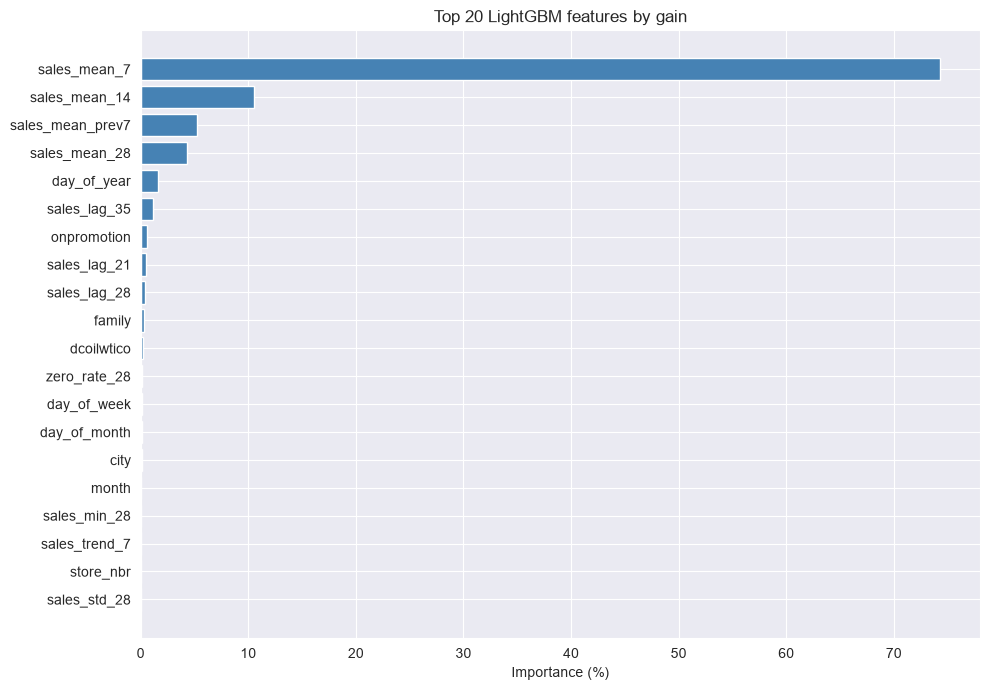

In [8]:
importance = (
    pl.DataFrame({
        'feature': feature_columns,
        'importance_gain': model.booster_.feature_importance(importance_type='gain'),
    })
    .with_columns(
        (pl.col('importance_gain') / pl.col('importance_gain').sum() * 100)
        .alias('importance_pct')
    )
    .sort('importance_gain', descending=True)
)
display(importance.head(20))

top_importance = importance.head(20).sort('importance_gain').to_pandas()
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(top_importance['feature'], top_importance['importance_pct'], color='steelblue')
ax.set_title('Top 20 LightGBM features by gain')
ax.set_xlabel('Importance (%)')
fig.tight_layout()
fig.savefig(FIGURES_DIR / 'lightgbm_feature_importance.png', dpi=150, bbox_inches='tight')
plt.show()

## 9. Save validation artifacts

The validation predictions and diagnostic tables are saved even if the model does not beat the baseline, so the next iteration can be compared reproducibly.

In [9]:
evaluation.write_parquet(PROCESSED_DIR / 'lightgbm_validation_predictions.parquet')
family_error.write_csv(REPORTS_DIR / 'lightgbm_error_by_family.csv')
horizon_error.write_csv(REPORTS_DIR / 'lightgbm_error_by_horizon.csv')
importance.write_csv(REPORTS_DIR / 'lightgbm_feature_importance.csv')
joblib.dump(model, MODELS_DIR / 'lightgbm_validation.joblib')

metrics = {
    'baseline_rmsle': float(baseline_check),
    'lightgbm_rmsle': float(model_rmsle),
    'relative_improvement_pct': float(improvement),
    'best_iteration': int(model.best_iteration_),
}
with open(REPORTS_DIR / 'lightgbm_validation_metrics.json', 'w', encoding='utf-8') as file:
    json.dump(metrics, file, indent=2)
print(metrics)

{'baseline_rmsle': 0.5215880144679157, 'lightgbm_rmsle': 0.42799084308670404, 'relative_improvement_pct': 17.94465304287982, 'best_iteration': 1508}


## 10. Final training and Kaggle submission

Run this section after reviewing the validation result. The final model adds the labeled validation window to training and uses exactly the number of trees selected by early stopping.

In [10]:
X_full = pd.concat([X_train, X_validation], ignore_index=True)
y_full_log = np.concatenate([y_train_log, y_validation_log])

final_model = lgb.LGBMRegressor(
    objective='regression_l2',
    n_estimators=model.best_iteration_,
    learning_rate=0.03,
    num_leaves=63,
    max_depth=-1,
    min_child_samples=40,
    subsample=0.85,
    colsample_bytree=0.85,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=SEED,
    n_jobs=-1,
    verbosity=-1,
)
final_model.fit(
    X_full,
    y_full_log,
    categorical_feature=CATEGORICAL_COLUMNS,
)

test_pred_log = final_model.predict(X_test)
test_pred = np.maximum(0, np.expm1(test_pred_log))
assert len(test_pred) == 28_512
assert np.isfinite(test_pred).all()
assert (test_pred >= 0).all()

submission = pl.DataFrame({
    'id': test_pl['id'],
    'sales': test_pred,
}).sort('id')

assert submission.height == 28_512
assert submission['id'].n_unique() == 28_512
submission.write_csv(PROCESSED_DIR / 'submission_lightgbm.csv')
joblib.dump(final_model, MODELS_DIR / 'lightgbm_final.joblib')

display(submission.head())
print('Submission:', PROCESSED_DIR / 'submission_lightgbm.csv')
print('Prediction range:', float(test_pred.min()), 'to', float(test_pred.max()))

id,sales
i64,f64
3000888,4.114953
3000889,0.034172
3000890,6.692928
3000891,2163.329883
3000892,0.019513


Submission: retail-demand-forecasting/data/processed/submission_lightgbm.csv
Prediction range: 0.0 to 14283.855350835564


## Decision rule

- If LightGBM RMSLE is below `0.521588`, it improves upon the baseline and becomes the current candidate model.
- If it is higher, inspect family errors and feature importance before tuning. Do not judge the model by training error.
- The Kaggle score is a final external check, not a replacement for temporal validation.